# Fase 1: Análise Exploratória de Dados (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("../data/credit_risk_dataset.csv")

# 1. Dimensões e tipos de dados
print(f"Dimensões da base: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
print("--- Tipos de Dados e Nulos ---")
info_df = pd.DataFrame({
    "Tipo": df.dtypes,
    "Nulos": df.isnull().sum(),
    "% Nulos": (df.isnull().mean() * 100).round(2)
})
display(info_df)

# 2. Duplicadas
print(f"\nLinhas duplicadas exatas: {df.duplicated().sum()}")

# 3. Sumário estatístico (numéricas e categóricas)
print("\n--- Estatísticas Descritivas (Numéricas) ---")
display(df.describe().T)

print("\n--- Estatísticas Descritivas (Categóricas) ---")
display(df.describe(include="object").T)

Dimensões da base: 32581 linhas e 12 colunas

--- Tipos de Dados e Nulos ---


,Tipo,Nulos,% Nulos
person_age,int64,0,0.00
person_income,int64,0,0.00
person_home_ownership,str,0,0.00
person_emp_length,float64,895,2.75
loan_intent,str,0,0.00
loan_grade,str,0,0.00
loan_amnt,int64,0,0.00
loan_int_rate,float64,3116,9.56
loan_status,int64,0,0.00
loan_percent_income,float64,0,0.00



Linhas duplicadas exatas: 165

--- Estatísticas Descritivas (Numéricas) ---


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00



--- Estatísticas Descritivas (Categóricas) ---


C:\Users\André\AppData\Local\Temp\ipykernel_5540\1403297822.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


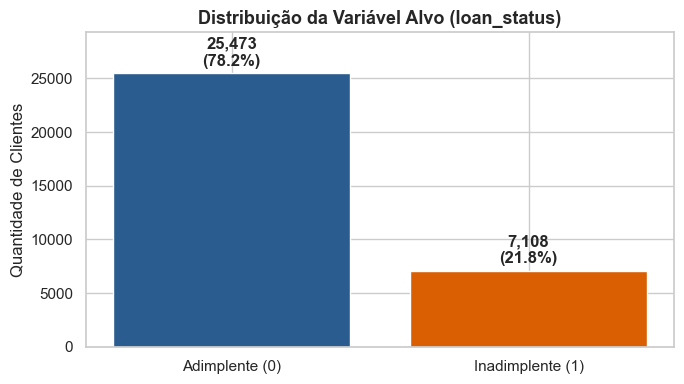

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["loan_status"].value_counts()
pcts = df["loan_status"].value_counts(normalize=True) * 100

bars = ax.bar(["Adimplente (0)", "Inadimplente (1)"], counts.values, color=["#2b5c8f", "#d95f02"])
ax.set_title("Distribuição da Variável Alvo (loan_status)", fontsize=13, fontweight="bold")
ax.set_ylabel("Quantidade de Clientes")
ax.set_ylim(0, counts.max() * 1.15)

for bar, count, pct in zip(bars, counts.values, pcts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 400,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

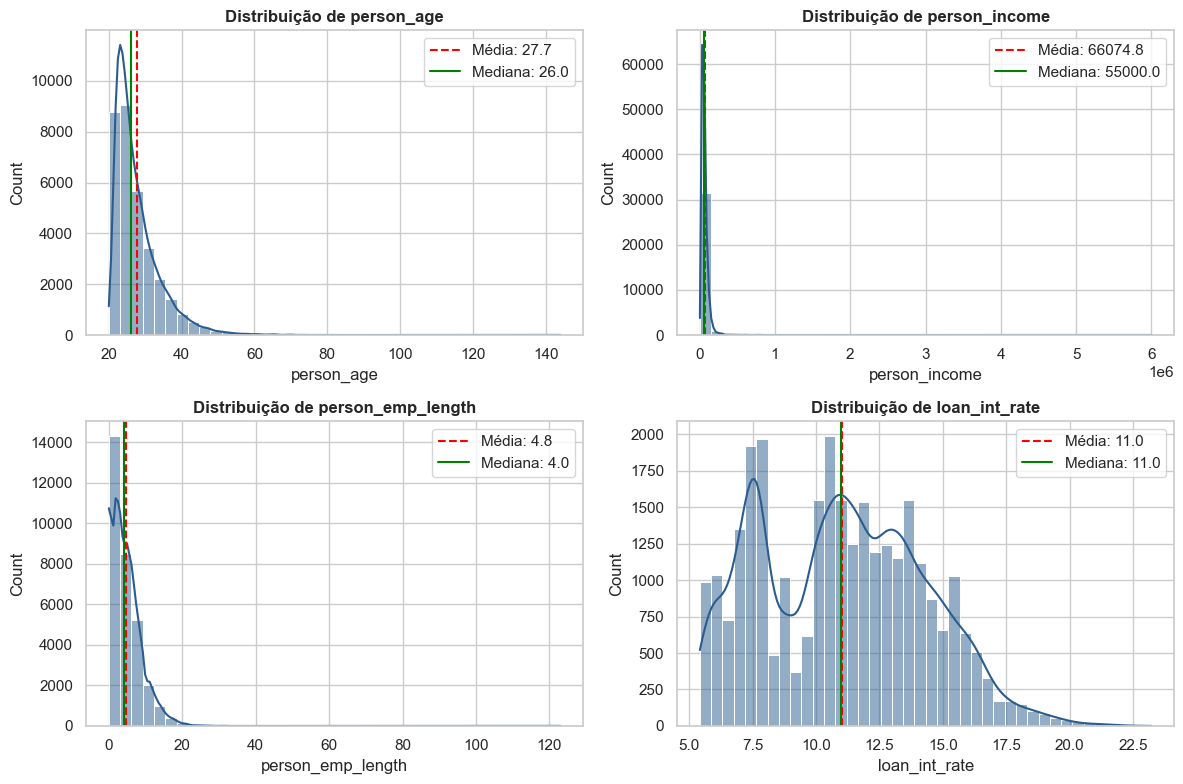

In [3]:
cols_num = ["person_age", "person_income", "person_emp_length", "loan_int_rate"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), cols_num):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color="#2b5c8f")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Média: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="green", linestyle="-", label=f"Mediana: {df[col].median():.1f}")
    ax.set_title(f"Distribuição de {col}", fontweight="bold")
    ax.legend()

plt.tight_layout()
plt.show()

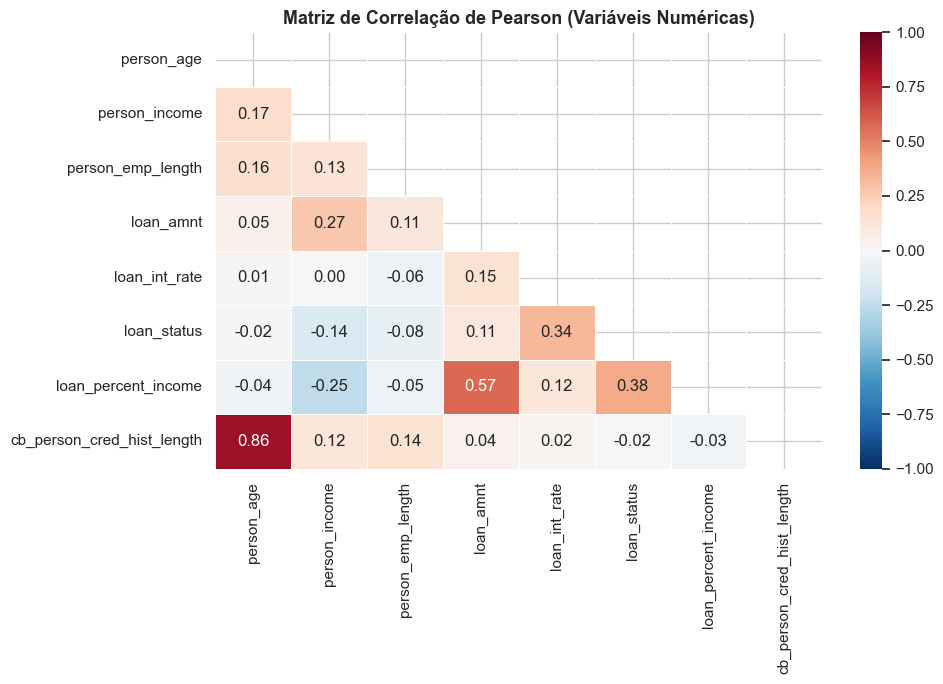

In [4]:
plt.figure(figsize=(10, 7))
corr_matrix = df.select_dtypes(include=[np.number]).corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Matriz de Correlação de Pearson (Variáveis Numéricas)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

C:\Users\André\AppData\Local\Temp\ipykernel_5540\2881888085.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\André\AppData\Local\Temp\ipykernel_5540\2881888085.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


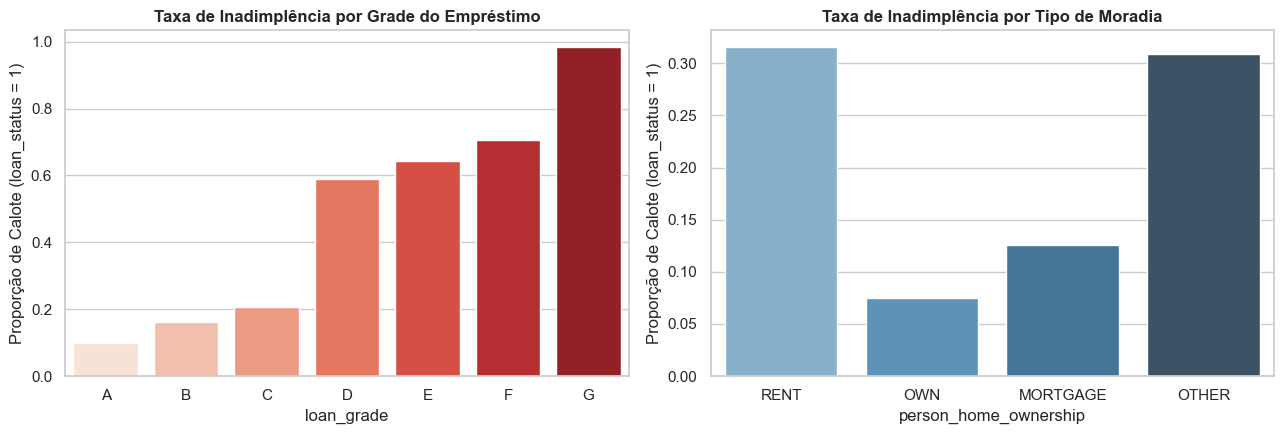

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(
    data=df,
    x="loan_grade",
    y="loan_status",
    order=sorted(df["loan_grade"].unique()),
    ax=axes[0],
    palette="Reds",
    errorbar=None
)
axes[0].set_title("Taxa de Inadimplência por Grade do Empréstimo", fontweight="bold")
axes[0].set_ylabel("Proporção de Calote (loan_status = 1)")

sns.barplot(
    data=df,
    x="person_home_ownership",
    y="loan_status",
    ax=axes[1],
    palette="Blues_d",
    errorbar=None
)
axes[1].set_title("Taxa de Inadimplência por Tipo de Moradia", fontweight="bold")
axes[1].set_ylabel("Proporção de Calote (loan_status = 1)")

plt.tight_layout()
plt.show()

### Análise Exploratória e Estratégia de Preparação

A base de dados possui **32.581 registros e 12 variáveis**, sendo 8 numéricas e 4 categóricas. A análise inicial revelou quatro pontos críticos que guiarão o pré-processamento na Fase 2:

1. **Desbalanceamento da Variável Alvo:** A classe `loan_status` apresenta **78,18% de clientes adimplentes (0)** contra **21,82% de inadimplentes (1)**. Como um modelo treinado diretamente nessa proporção tenderia a ignorar a classe minoritária (gerando muitos Falsos Negativos), será obrigatório aplicar reamostragem (como SMOTE) exclusivamente sobre o conjunto de treino na Fase 4.
2. **Redundância e Dados Ausentes:** Foram identificadas **165 linhas duplicadas** que precisam ser removidas para evitar viés de contagem. Além disso, há valores nulos em `person_emp_length` (**895 registros / 2,75%**) e `loan_int_rate` (**3.116 registros / 9,56%**). Como as distribuições apresentam assimetria positiva e valores discrepantes (especialmente em `person_emp_length`, onde a média é 4,79 anos contra mediana de 4,00), a imputação pela **mediana** será mais robusta do que a média.
3. **Anomalias e Outliers Severos:** Os resumos estatísticos e histogramas evidenciaram erros de preenchimento ou outliers extremos: clientes com idade (`person_age`) de **123 e 144 anos**, tempo de emprego (`person_emp_length`) de **123 anos** (inconsistente com clientes de 21 e 22 anos) e renda anual (`person_income`) chegando a **US$ 6.000.000**. Esses extremos distorceriam fortemente o cálculo de distância euclidiana do algoritmo **KNN**, exigindo tratamento criterioso na próxima etapa.
4. **Fatores Preditivos Relevantes:** A matriz de correlação de Pearson indica que o comprometimento da renda (`loan_percent_income`, r = 0,38) e a taxa de juros (`loan_int_rate`, r = 0,34) são as variáveis numéricas mais associadas ao calote. Nas categóricas, a inadimplência salta de **9,96% no grau A** para **98,44% no grau G**, e clientes que moram de aluguel (`RENT`, **31,57%**) apresentam mais que o quadruplo da taxa de calote de quem possui imóvel próprio (`OWN`, **7,47%**).

# Fase 2: Tratamento e Limpeza (Data Prep)

In [6]:
# 1. Remoção de duplicadas
antes_dup = len(df)
df = df.drop_duplicates().copy()
print(f"Linhas removidas por duplicidade: {antes_dup - len(df)} | Restantes: {len(df)}")

# 2. Imputação de valores nulos pela mediana
# Justificativa: distribuições assimétricas e com valores extremos tornam a mediana mais robusta que a média
for col in ["person_emp_length", "loan_int_rate"]:
    mediana_col = df[col].median()
    nulos_antes = df[col].isnull().sum()
    df[col] = df[col].fillna(mediana_col)
    print(f"Coluna '{col}': {nulos_antes} nulos preenchidos com mediana = {mediana_col:.2f}")

print("\nTotal de nulos restantes após imputação:", df.isnull().sum().sum())

Linhas removidas por duplicidade: 165 | Restantes: 32416
Coluna 'person_emp_length': 887 nulos preenchidos com mediana = 4.00
Coluna 'loan_int_rate': 3095 nulos preenchidos com mediana = 10.99

Total de nulos restantes após imputação: 0


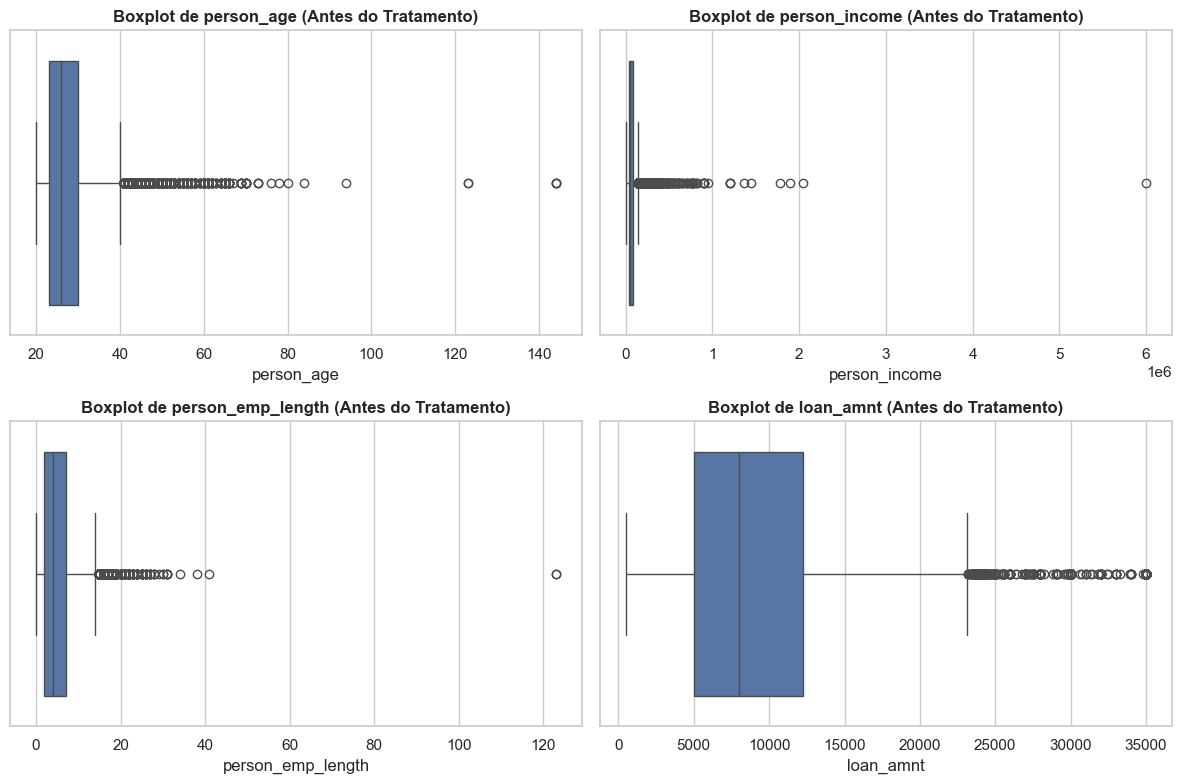

Registros removidos por inconsistência/anomalia extrema: 7
Base limpa final (Fase 2): 32409 linhas e 12 colunas


In [7]:
# Boxplots para inspeção visual de outliers antes do filtro
cols_box = ["person_age", "person_income", "person_emp_length", "loan_amnt"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), cols_box):
    sns.boxplot(x=df[col], ax=ax, color="#4c72b0")
    ax.set_title(f"Boxplot de {col} (Antes do Tratamento)", fontweight="bold")

plt.tight_layout()
plt.show()

# Regra de tratamento de anomalias:
# - Remove idades impossíveis (> 100 anos)
# - Remove tempo de emprego impossível (> 60 anos ou maior que idade - 14 anos)
antes_out = len(df)
df = df[
    (df["person_age"] <= 100) &
    (df["person_emp_length"] <= 60) &
    (df["person_emp_length"] <= (df["person_age"] - 14))
].copy()

print(f"Registros removidos por inconsistência/anomalia extrema: {antes_out - len(df)}")
print(f"Base limpa final (Fase 2): {df.shape[0]} linhas e {df.shape[1]} colunas")

### Decisões de Limpeza e Impacto nos Modelos

* **Duplicadas:** Foram removidas **165 linhas duplicadas exatas**, evitando que registros repetidos enviassem o treinamento e inflassem artificialmente a importância de certos perfis.
* **Valores Nulos:** As colunas `person_emp_length` e `loan_int_rate` tiveram seus valores ausentes imputados pela **mediana** (4,00 anos e 10,99%, respectivamente). Como há assimetria positiva e valores discrepantes, a mediana evita que extremos puxem a imputação para valores irreais.
* **Outliers:** Foram removidos **7 registros com anomalias impossíveis** (idades acima de 100 anos, como 123 e 144, e tempo de emprego de 123 anos incompatível com a idade declarada), mantendo os demais casos reais da base (como rendas mais elevadas).
* **Impacto em KNN vs. Árvore de Decisão:** O **KNN** calcula distâncias (como euclidiana) e é altamente sensível a outliers e escalas, o que distorceria a vizinhança se extremos não fossem controlados (e escalonados depois). Já as **Árvores de Decisão** dividem os dados por cortes/limiares em cada variável, sendo naturalmente mais robustas a valores extremos isolados.

# Fase 3: Feature Engineering (Coluna Calculada)

In [8]:
# Garantia extra contra divisão por zero ou valores infinitos
df["comprometimento_renda"] = np.where(
    df["person_income"] > 0,
    (df["loan_amnt"] / df["person_income"]) * 100,
    np.nan
)

# Substitui eventual infinito por NaN e trata se houver algum valor inválido
df["comprometimento_renda"] = df["comprometimento_renda"].replace([np.inf, -np.inf], np.nan)
if df["comprometimento_renda"].isnull().sum() > 0:
    df["comprometimento_renda"] = df["comprometimento_renda"].fillna(df["comprometimento_renda"].median())

print("Nulos ou infinitos em 'comprometimento_renda':",
      df["comprometimento_renda"].isnull().sum(),
      np.isinf(df["comprometimento_renda"]).sum())
print("\nResumo de 'comprometimento_renda' (%):")
display(df["comprometimento_renda"].describe())

Nulos ou infinitos em 'comprometimento_renda': 0 0

Resumo de 'comprometimento_renda' (%):


count    32409.000000
mean        17.059651
std         10.705381
min          0.078947
25%          8.972231
50%         14.814815
75%         22.916667
max         83.000000
Name: comprometimento_renda, dtype: float64

### Nova Variável: `comprometimento_renda`

Criamos a coluna `comprometimento_renda = (loan_amnt / person_income) * 100` após o tratamento de dados ausentes e com proteção explícita contra divisão por zero e valores infinitos (`NaN`/`inf`). Essa métrica expressa de forma direta qual percentual da renda anual do cliente é consumido pelo valor do empréstimo solicitado, reforçando o sinal de capacidade de pagamento para os modelos preditivos.